# Escolha do k

## Importando as bibliotecas e os dados

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.knn_utils import criar_rodar, criar_cv_f1

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

In [2]:
train_df = pd.read_csv("../data/processed/train.csv", index_col="id")
test_df = pd.read_csv("../data/processed/test.csv", index_col="id")
X_train, y_train = train_df.drop(columns="classe"), train_df["classe"]
X_test, y_test = test_df.drop(columns="classe"), test_df["classe"]

rodar = criar_rodar(X_train, X_test, y_train, y_test)
cv_f1 = criar_cv_f1(X_train, y_train)

ks = [1, 3, 5, 7, 9, 11, 15, 21, 31]

## Investigação do hiperparâmetro k

Usamos o `MinMaxScaler`, que foi o melhor na etapa anterior, com distância euclidiana e votação uniforme. Testamos os valores de k pedidos e registramos F1 de treino, F1 de teste e o gap.

In [3]:
esc = pd.read_csv("../data/processed/escalonamento.csv", index_col="modelo")
res_k = {k: rodar("minmax", k=k) for k in ks if k != 5}
res_k[5] = esc.loc["B - MinMaxScaler"].to_dict()
res_k = pd.DataFrame({k: res_k[k] for k in ks}).T[["f1_treino", "f1_teste", "gap", "acc_teste", "prec_teste", "rec_teste"]]
res_k.index.name = "k"
res_k.to_csv("../data/processed/k_teste.csv")

tab_k = res_k[["f1_treino", "f1_teste", "gap"]].copy()
tab_k.columns = ["F1 treino", "F1 teste", "Gap"]
tab_k

,F1 treino,F1 teste,Gap
k,,,
1,1.0000,0.7609,0.2391
3,0.8815,0.8248,0.0568
5,0.8621,0.8000,0.0621
7,0.8383,0.7931,0.0452
9,0.8491,0.7933,0.0558
11,0.8425,0.8058,0.0367
15,0.8230,0.8187,0.0042
21,0.8077,0.7799,0.0278
31,0.8072,0.7673,0.0399


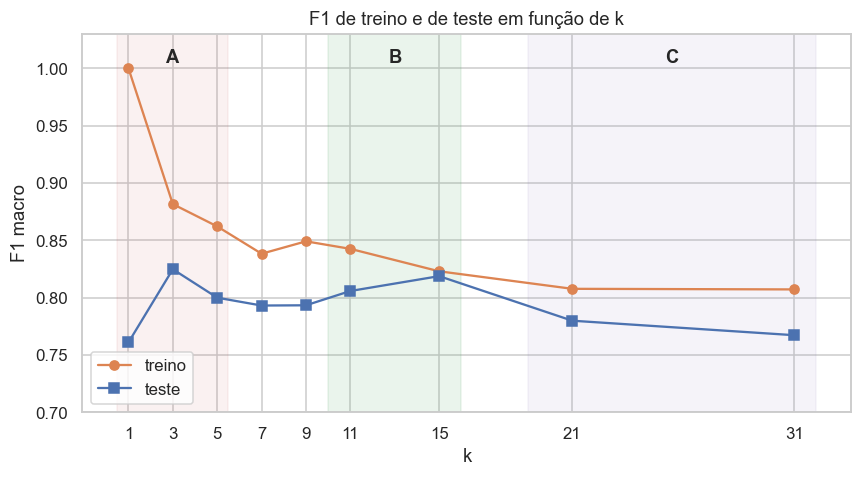

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(ks, tab_k["F1 treino"], marker="o", label="treino", color="#DD8452")
ax.plot(ks, tab_k["F1 teste"], marker="s", label="teste", color="#4C72B0")
ax.axvspan(0.5, 5.5, color="#C44E52", alpha=.08)
ax.axvspan(10, 16, color="#55A868", alpha=.12)
ax.axvspan(19, 32, color="#8172B3", alpha=.08)
for x, txt in [(3, "A"), (13, "B"), (25.5, "C")]:
    ax.text(x, 1.005, txt, ha="center", fontsize=12, fontweight="bold")
ax.set_xticks(ks)
ax.set_xlabel("k")
ax.set_ylabel("F1 macro")
ax.set_ylim(0.7, 1.03)
ax.set_title("F1 de treino e de teste em função de k")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

Para confirmar que a escolha de k não depende só de uma divisão em particular (o teste tem apenas 155 linhas), repetimos a comparação com validação cruzada estratificada de 5 dobras no conjunto de treino, com o escalonador dentro do `Pipeline`. Esse passo usa apenas dados de treino.

In [5]:
cv_k = pd.DataFrame({k: cv_f1("minmax", k) for k in ks}, index=["F1 médio (cv)", "desvio (cv)"]).T
cv_k.index.name = "k"
cv_k.to_csv("../data/processed/k_cv.csv")
cv_k

,F1 médio (cv),desvio (cv)
k,,
1,0.7563,0.0418
3,0.7755,0.0272
5,0.7777,0.0271
7,0.7733,0.0227
9,0.7797,0.0164
11,0.7798,0.0263
15,0.7821,0.0230
21,0.7813,0.0250
31,0.7579,0.0340


In [6]:
comp_esc = pd.DataFrame({
    "MinMax (teste)": tab_k["F1 teste"].to_numpy(),
    "Standard (teste)": [rodar("standard", k=k)["f1_teste"] for k in ks],
    "MinMax (cv)": cv_k["F1 médio (cv)"].to_numpy(),
    "Standard (cv)": [cv_f1("standard", k)[0] for k in ks],
}, index=pd.Index(ks, name="k"))
comp_esc

,MinMax (teste),Standard (teste),MinMax (cv),Standard (cv)
k,,,,
1,0.7609,0.7607,0.7563,0.7478
3,0.8248,0.7799,0.7755,0.7846
5,0.8000,0.7677,0.7777,0.7798
7,0.7931,0.8187,0.7733,0.7556
9,0.7933,0.8176,0.7797,0.7602
11,0.8058,0.8181,0.7798,0.7623
15,0.8187,0.8118,0.7821,0.7641
21,0.7799,0.8181,0.7813,0.7650
31,0.7673,0.7666,0.7579,0.7544


* k = 1–5: maior risco de overfitting. O k = 3 teve um pico no teste, mas não se manteve na validação cruzada.
* k = 11–15: melhor equilíbrio entre treino, teste e validação. Escolhemos k = 15.
* k = 21–31: os resultados caem, indicando underfitting.
* Em geral, k pequeno deixa o modelo mais complexo, com viés baixo e variância alta (overfitting); k grande deixa o modelo mais simples, com viés alto e variância menor (underfitting). O equilíbrio ficou em k = 15.